In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\rauna\OneDrive\Desktop\MLProject\data\online_retail_working.csv")
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1027012,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
1027013,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1027014,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1027015,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [3]:
categorical_cols = ['Customer ID','Country','Description','StockCode','Invoice']

In [4]:
numerical_cols = ['Quantity', 'Price', 'TotalAmount']

# Univariate

In [6]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(10))


--- Customer ID ---
Customer ID
17841.0    12638
14911.0    11442
12748.0     6660
14606.0     6500
14096.0     5128
15311.0     4579
14156.0     4118
14646.0     3885
13089.0     3390
16549.0     3098
Name: count, dtype: int64

--- Country ---
Country
United Kingdom    942329
EIRE               17662
Germany            17331
France             14024
Netherlands         5132
Spain               3753
Switzerland         3174
Belgium             3109
Portugal            2528
Australia           1887
Name: count, dtype: int64

--- Description ---
Description
WHITE HANGING HEART T-LIGHT HOLDER    5735
REGENCY CAKESTAND 3 TIER              4291
JUMBO BAG RED RETROSPOT               3384
ASSORTED COLOUR BIRD ORNAMENT         2867
PARTY BUNTING                         2728
STRAWBERRY CERAMIC TRINKET BOX        2533
LUNCH BAG  BLACK SKULL.               2447
JUMBO STORAGE BAG SUKI                2386
JUMBO SHOPPER VINTAGE RED PAISLEY     2231
HEART OF WICKER SMALL                 2214
Name: c

In [7]:
df[numerical_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Quantity,1027017.0,10.446107,168.633972,-80995.000,1.00,3.00,10.00,80995.0
Price,1027017.0,4.795523,93.108053,0.001,1.25,2.10,4.15,38970.0
TotalAmount,1027017.0,18.514017,285.547609,-168469.600,3.75,9.95,17.70,168469.6


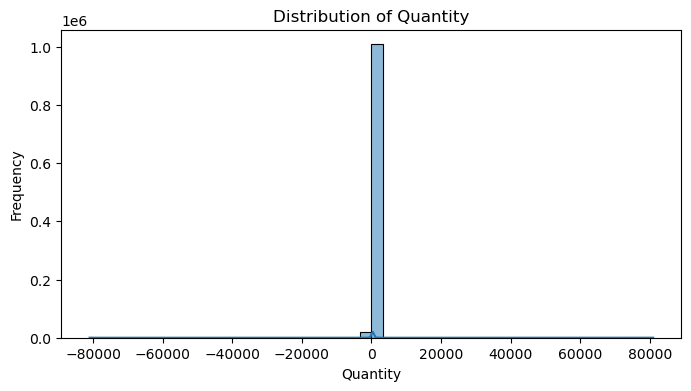

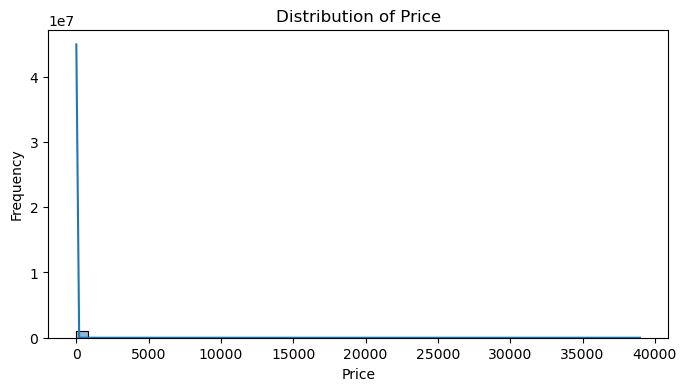

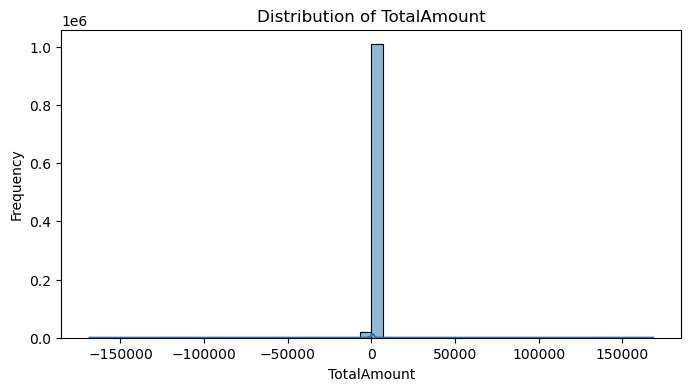

In [8]:
for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=50, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [9]:
df[numerical_cols].skew()

Quantity         5.538291
Price          182.740778
TotalAmount     -1.072353
dtype: float64

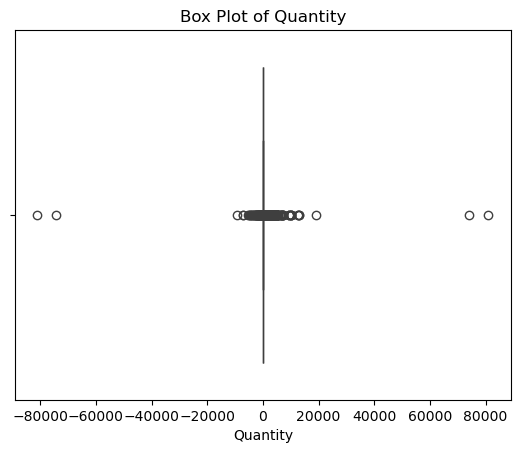

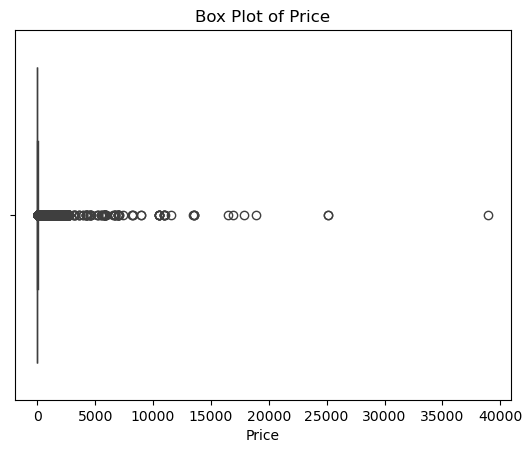

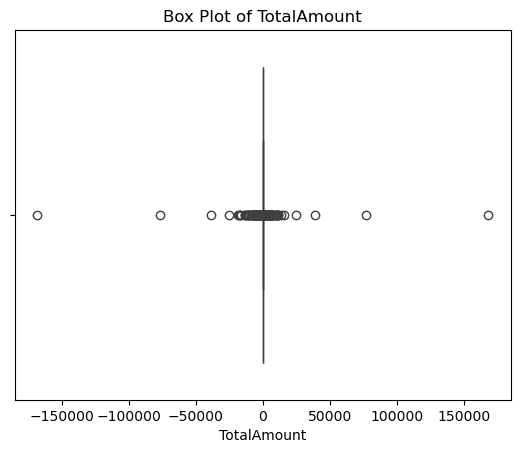

In [10]:
for col in numerical_cols:
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

In [11]:
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} outliers")

Quantity: 111527 outliers
Price: 66191 outliers
TotalAmount: 89000 outliers


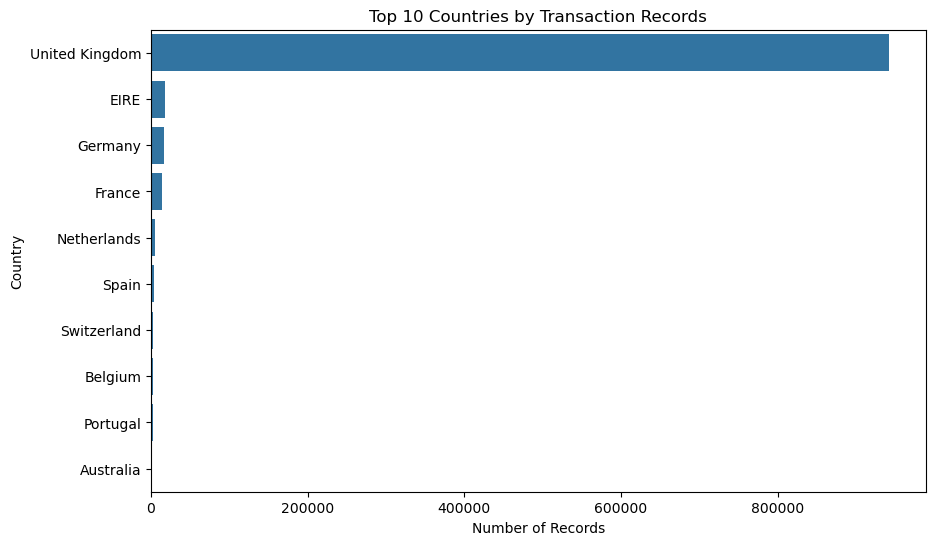

In [12]:
plt.figure(figsize=(10, 6))

country_counts = df['Country'].value_counts().head(10)

sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title('Top 10 Countries by Transaction Records')
plt.xlabel('Number of Records')
plt.ylabel('Country')
plt.show()

Text(0.5, 1.0, 'Top 10 Most Frequently Purchased Products')

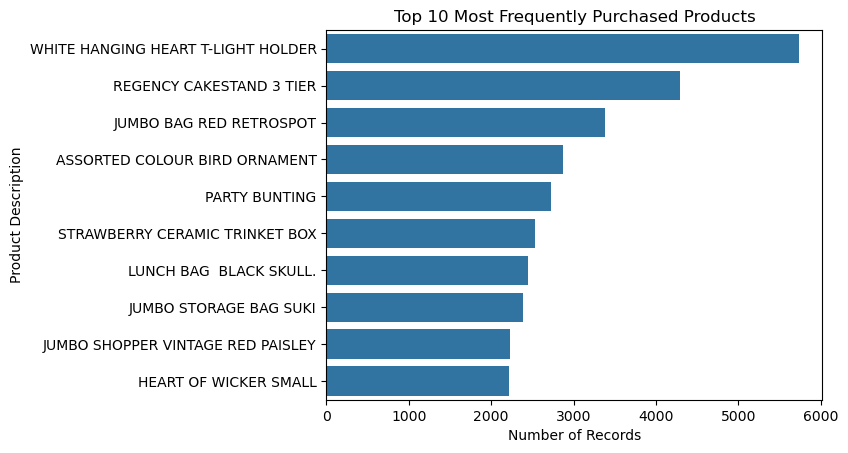

In [13]:
top_products=df["Description"].value_counts().head(10)
sns.barplot(x=top_products.values, y=top_products.index)
plt.xlabel("Number of Records")
plt.ylabel("Product Description")
plt.title("Top 10 Most Frequently Purchased Products")

# Bivariate

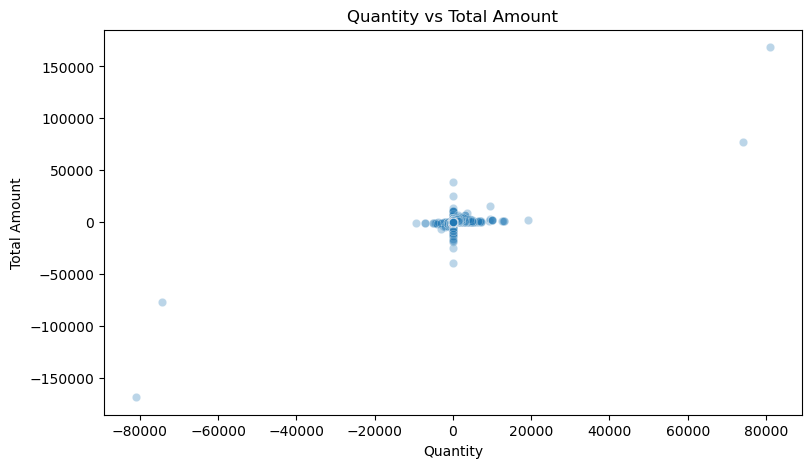

In [15]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='TotalAmount',
    alpha=0.3
)

plt.title('Quantity vs Total Amount')
plt.xlabel('Quantity')
plt.ylabel('Total Amount')
plt.show()

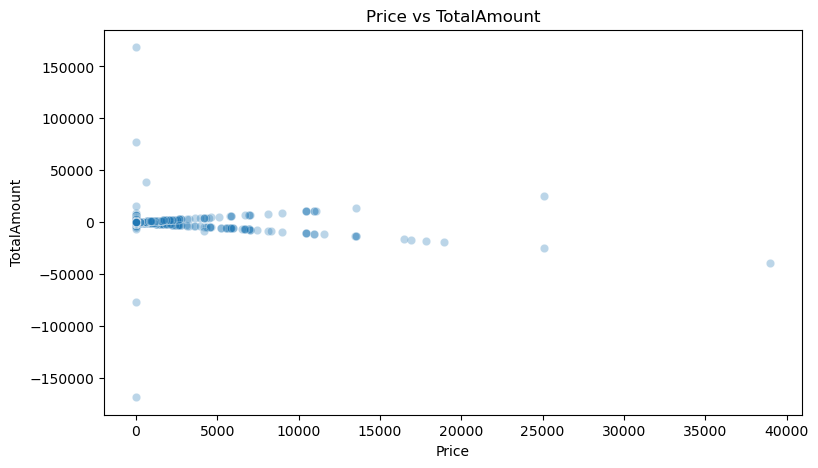

In [16]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Price',
    y='TotalAmount',
    alpha=0.3
)

plt.title('Price vs TotalAmount')
plt.show()

In [17]:
df[['Price', 'TotalAmount']].corr()

,Price,TotalAmount
Price,1.000000,-0.138828
TotalAmount,-0.138828,1.000000


In [18]:
df[['Quantity', 'TotalAmount']].corr()

,Quantity,TotalAmount
Quantity,1.000000,0.830131
TotalAmount,0.830131,1.000000


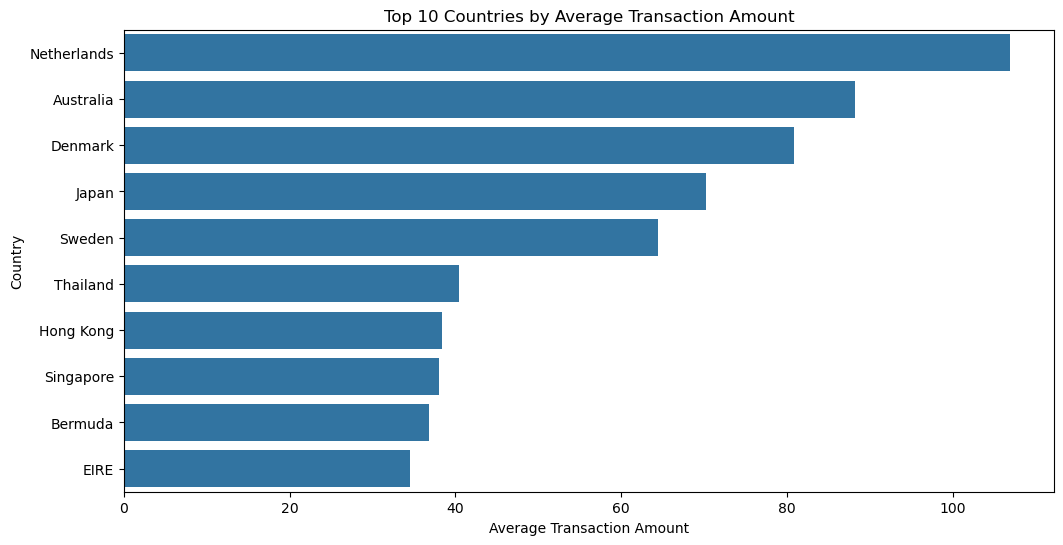

In [19]:
country_avg = (
    df.groupby('Country')['TotalAmount']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=country_avg.values, y=country_avg.index)

plt.title('Top 10 Countries by Average Transaction Amount')
plt.xlabel('Average Transaction Amount')
plt.ylabel('Country')
plt.show()

In [20]:
country_analysis = df.groupby('Country').agg(
    Transaction_Count=('Invoice', 'count'),
    Average_Amount=('TotalAmount', 'mean'),
    Total_Amount=('TotalAmount', 'sum')
).sort_values('Transaction_Count', ascending=False)

country_analysis.head(10)

,Transaction_Count,Average_Amount,Total_Amount
Country,,,
United Kingdom,942329,17.132802,1.614474e+07
EIRE,17662,34.534808,6.099538e+05
Germany,17331,23.770074,4.119592e+05
France,14024,22.941628,3.217334e+05
Netherlands,5132,106.845421,5.483307e+05
Spain,3753,24.250850,9.101344e+04
Switzerland,3174,31.317914,9.940306e+04
Belgium,3109,20.330939,6.320889e+04
Portugal,2528,20.333734,5.140368e+04


In [21]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

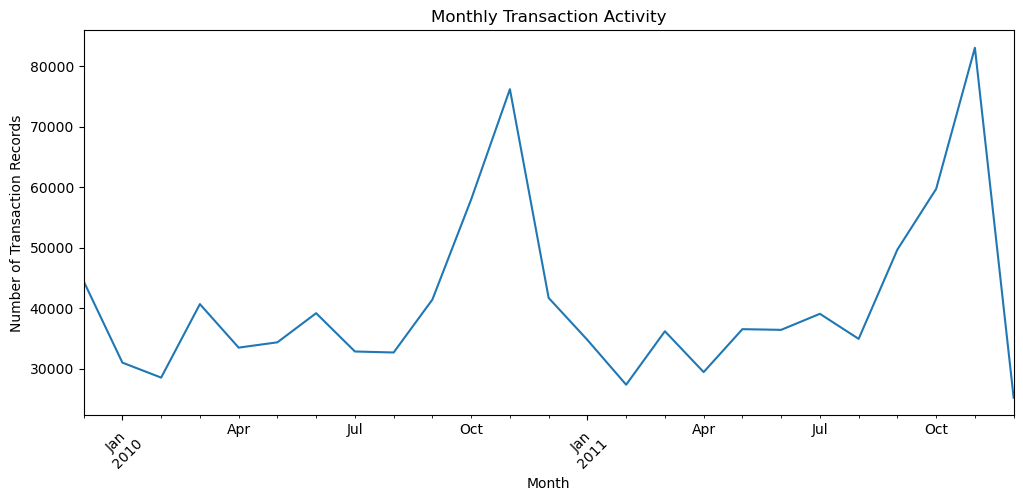

In [22]:
monthly_transactions = df.groupby(
    df['InvoiceDate'].dt.to_period('M')
)['Invoice'].count()

monthly_transactions.plot(figsize=(12, 5))

plt.title('Monthly Transaction Activity')
plt.xlabel('Month')
plt.ylabel('Number of Transaction Records')
plt.xticks(rotation=45)
plt.show()

In [23]:
df_customer = df.dropna(subset=['Customer ID']).copy()

In [24]:
print("Total unique customers:",
      df_customer['Customer ID'].nunique())

Total unique customers: 5939


In [25]:
customer_analysis = df_customer.groupby('Customer ID').agg(
    Total_Purchases=('Invoice', 'nunique'),
    Total_Spending=('TotalAmount', 'sum'),
    Average_Order_Value=('TotalAmount', 'mean'),
    Total_Quantity=('Quantity', 'sum')
)

customer_analysis.head()

,Total_Purchases,Total_Spending,Average_Order_Value,Total_Quantity
Customer ID,,,,
12346.0,17,-51.74,-1.100851,53
12347.0,8,4921.53,22.169054,2967
12348.0,5,2019.40,39.596078,2714
12349.0,5,4404.54,24.469667,1619
12350.0,1,334.40,19.670588,197


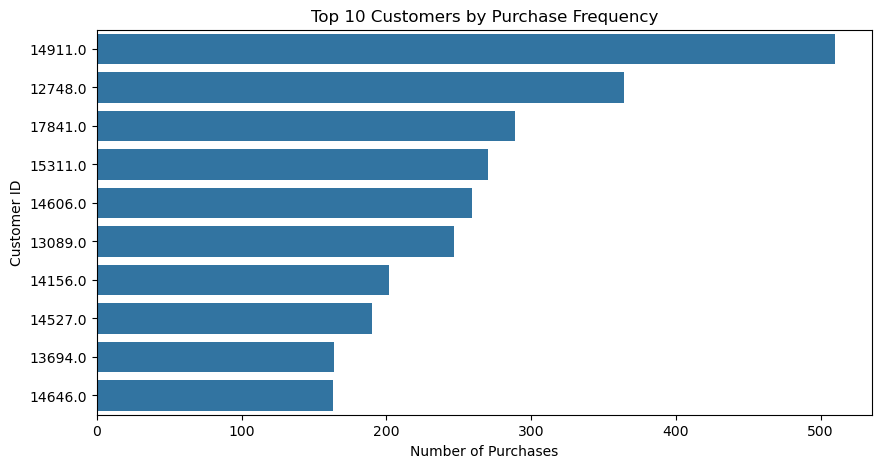

In [26]:
top_frequency = customer_analysis.nlargest(10, 'Total_Purchases')

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_frequency['Total_Purchases'],
    y=top_frequency.index.astype(str)
)

plt.title('Top 10 Customers by Purchase Frequency')
plt.xlabel('Number of Purchases')
plt.ylabel('Customer ID')
plt.show()

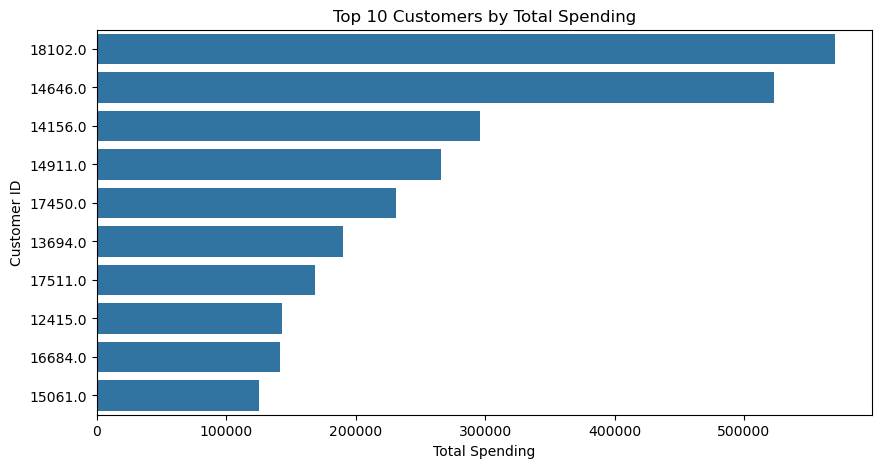

In [27]:
top_spending = customer_analysis.nlargest(10, 'Total_Spending')

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_spending['Total_Spending'],
    y=top_spending.index.astype(str)
)

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Total Spending')
plt.ylabel('Customer ID')
plt.show()

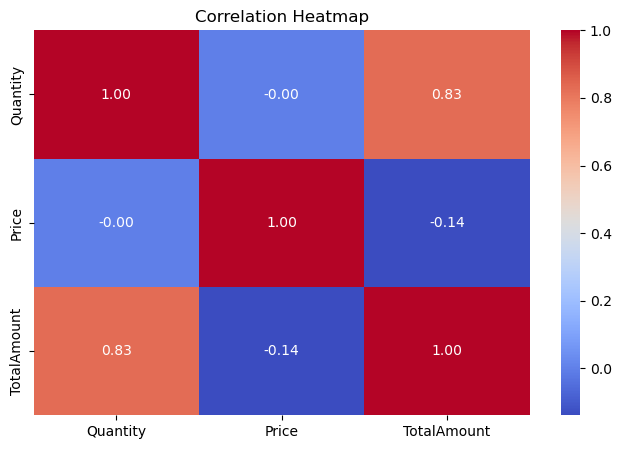

In [28]:
correlation_matrix = df[
    ['Quantity', 'Price', 'TotalAmount']
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

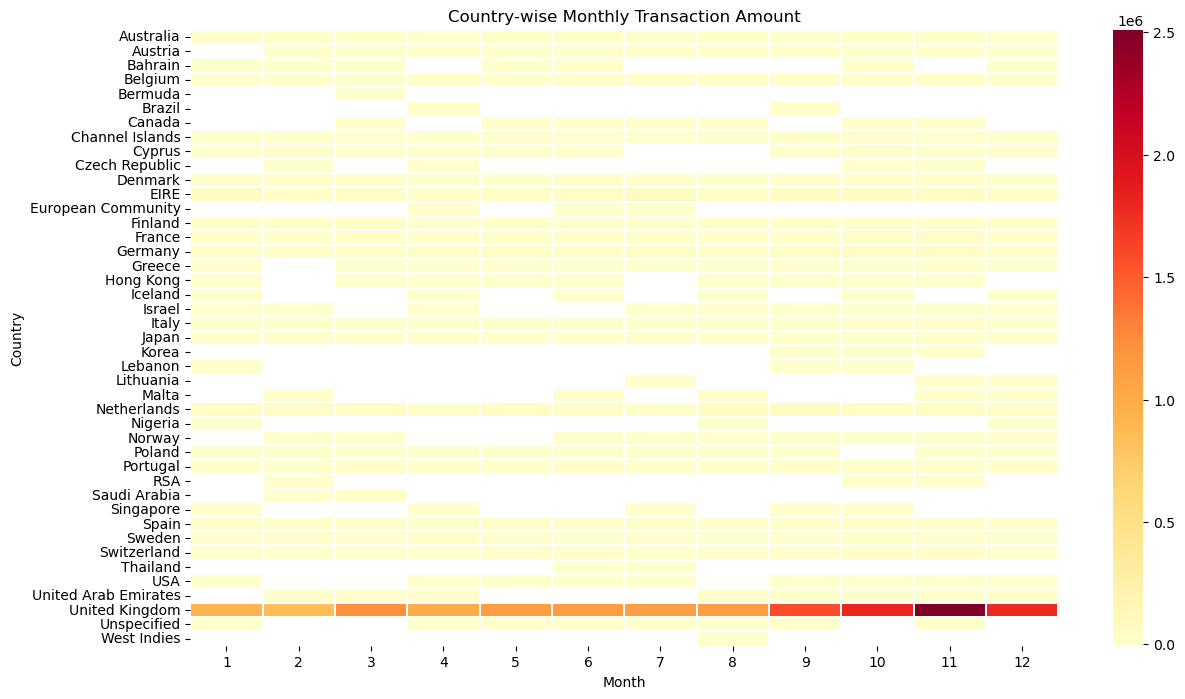

In [29]:
country_month = df.pivot_table(
    index='Country',
    columns='Month',
    values='TotalAmount',
    aggfunc='sum'
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    country_month,
    cmap='YlOrRd',
    linewidths=0.3
)

plt.title('Country-wise Monthly Transaction Amount')
plt.xlabel('Month')
plt.ylabel('Country')
plt.show()

In [30]:
from scipy.stats import ttest_ind

uk = df_customer.loc[
    df_customer['Country'] == 'United Kingdom',
    'TotalAmount'
]

other = df_customer.loc[
    df_customer['Country'] != 'United Kingdom',
    'TotalAmount'
]

statistic, p_value = ttest_ind(
    uk,
    other,
    equal_var=False
)

print("T-statistic:", statistic)
print("P-value:", p_value)

T-statistic: -27.94116712186371
P-value: 1.444885798301924e-171


In [31]:
print("UK Mean:", uk.mean())
print("Other Countries Mean:", other.mean())

print("UK Median:", uk.median())
print("Other Countries Median:", other.median())

UK Mean: 18.82849988897717
Other Countries Mean: 34.3440192914638
UK Median: 10.2
Other Countries Median: 17.4
